# 03 — Experiments B, C, E & F: Controlled Shift Replay & Lead-Time ($\Delta t$) Comparison
Replays `test_stream.parquet` window by window (2,000 flows/window) anchored around the chronological attack wave, injects controlled shifts (`covariate_benign` vs. `concept_proxy`), unlocks labels to detect $t_{\text{fail}}$, and compares `M3` vs. `M4` lead times ($\Delta t = t_{\text{fail}} - t_{\text{alarm}}$).

In [5]:
import sys
import json
from pathlib import Path

ML_SERVICE_ROOT = Path.cwd().resolve()
if ML_SERVICE_ROOT.name == "notebooks":
    ML_SERVICE_ROOT = ML_SERVICE_ROOT.parent
if str(ML_SERVICE_ROOT) not in sys.path:
    sys.path.insert(0, str(ML_SERVICE_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
from src.config import settings
from src.logger import setup_logging

setup_logging()
print("Connected to ML Service Root:", ML_SERVICE_ROOT)
from src.service.model_engine import IDSEngine
from src.service.monitors import DriftMonitorSuite
from src.service.shift_simulator import run_controlled_experiment

with open(settings.SPLITS_DIR / 'split_metadata.json', encoding='utf-8') as f:
    feature_cols = json.load(f)['feature_cols']
test_df = pd.read_parquet(settings.SPLITS_DIR / 'test_stream.parquet')
engine = IDSEngine.load(settings.ARTIFACTS_DIR / 'xgb_ids.joblib')
monitor = DriftMonitorSuite.load(settings.ARTIFACTS_DIR / 'reference_profile.joblib', settings.ARTIFACTS_DIR / 'thresholds.json', min_bucket_samples=settings.MIN_BUCKET_SAMPLES)

Connected to ML Service Root: C:\Users\gupta\Documents\College\BTP\code\ea-idrs\ml-service


In [6]:
exp_result = run_controlled_experiment(
    test_df=test_df,
    feature_cols=feature_cols,
    engine=engine,
    monitor=monitor,
    target_attack="DDoS",
    shift_type="concept_proxy",
    max_windows=40,
    recall_cutoff=0.80,
)

shift_start = exp_result["shift_start_window"]
t_fail = exp_result["t_fail"]
recall_cutoff = exp_result["recall_cutoff"]
replay_df = pd.DataFrame(exp_result["windows"])

print(f"Shift injected at window: {shift_start} | t_fail detected at window: {t_fail}")
print(f"Post-shift (M4 - M3) 95% Bootstrap CI: {exp_result['m4_minus_m3_margin_ci95']}")
display(pd.DataFrame(exp_result["monitor_comparison"]))

2026-11-24 21:31:58 | INFO     | src.service.shift_simulator:137 | Running experiment | attack=DDoS | shift=concept_proxy | windows=435..478 | shift_start=451
Shift injected at window: 451 | t_fail detected at window: None
Post-shift (M4 - M3) 95% Bootstrap CI: [-3.7886, -1.6308]


,monitor,empirical_far_pct,t_alarm,t_fail,lead_time_delta_t,missed_degradation,mean_score_post_shift
0,M1,0.00,457,None,None,False,1.6594
1,M2,37.50,452,None,None,False,23.3359
2,M3,43.75,451,None,None,False,12.4976
3,M4,62.50,451,None,None,False,9.7668


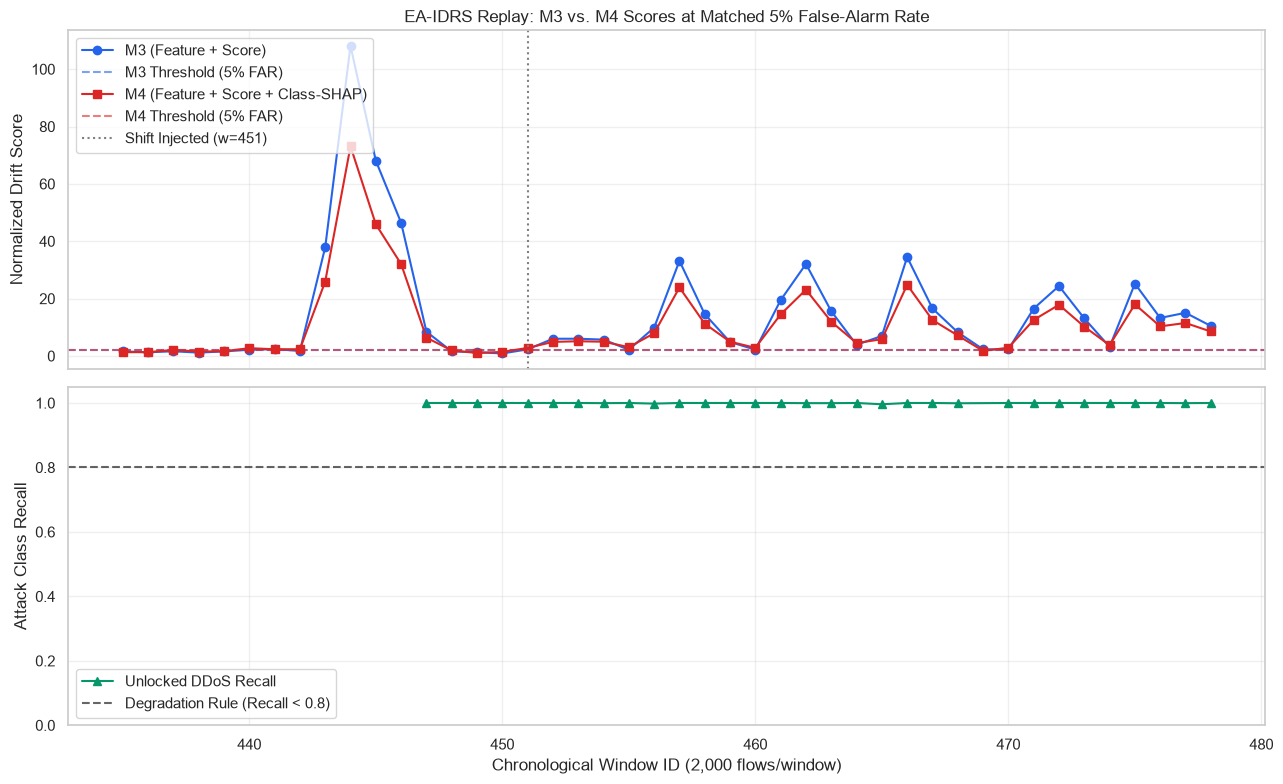

In [7]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

ax1.plot(replay_df["window_id"], replay_df["m3_score"], label="M3 (Feature + Score)", marker="o", color="#2563eb")
ax1.axhline(monitor.thresholds.m3_threshold, linestyle="--", color="#2563eb", alpha=0.6, label="M3 Threshold (5% FAR)")
ax1.plot(replay_df["window_id"], replay_df["m4_score"], label="M4 (Feature + Score + Class-SHAP)", marker="s", color="#dc2626")
ax1.axhline(monitor.thresholds.m4_threshold, linestyle="--", color="#dc2626", alpha=0.6, label="M4 Threshold (5% FAR)")
ax1.axvline(shift_start, color="gray", linestyle=":", label=f"Shift Injected (w={shift_start})")
if t_fail is not None:
    ax1.axvline(t_fail, color="black", linestyle="-.", label=f"t_fail (w={t_fail})")
ax1.set_ylabel("Normalized Drift Score")
ax1.set_title("EA-IDRS Replay: M3 vs. M4 Scores at Matched 5% False-Alarm Rate")
ax1.legend(loc="upper left")
ax1.grid(True, alpha=0.3)

valid_rec = replay_df.dropna(subset=["target_recall"])
ax2.plot(valid_rec["window_id"], valid_rec["target_recall"], label="Unlocked DDoS Recall", marker="^", color="#059669")
ax2.axhline(recall_cutoff, linestyle="--", color="black", alpha=0.6, label=f"Degradation Rule (Recall < {recall_cutoff})")
if t_fail is not None:
    ax2.axvline(t_fail, color="black", linestyle="-.")
ax2.set_ylabel("Attack Class Recall")
ax2.set_xlabel("Chronological Window ID (2,000 flows/window)")
ax2.set_ylim(0, 1.05)
ax2.legend(loc="lower left")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()